# 🚀 Модуль 6. Урок 3. Смешивание данных (Data Blending) и объединение источников в BI

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_06_bi_looker_studio/lesson_03_data_blending_joins_in_bi.ipynb)

## 📌 Бизнес-контекст и методология
Смешивание данных (Data Blending) в BI позволяет связать данные из разнородных источников:
например, рекламные расходы из Google Ads / Яндекс.Директ со статистикой фактических оплат в корпоративной CRM.
Ключевая аналитическая метрика — **ROAS (Return on Ad Spend = Revenue / Ad Spend)**.
Если не выполнить предварительную агрегацию по дате и каналу, в BI возникнет Cartesian Fan-out и задвоение расходов.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

customers_csv = ensure_dataset("customers.csv", subfolder="raw")
orders_csv = ensure_dataset("orders.csv", subfolder="raw")
saas_csv = ensure_dataset("saas_users.csv", subfolder="raw")

df_customers = pd.read_csv(customers_csv)
df_orders = pd.read_csv(orders_csv)
df_saas = pd.read_csv(saas_csv)
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Смоделируем объединение рекламных расходов и фактических продаж по каналам за последний квартал.

In [2]:
# Демонстрация: Смешивание маркетинговых расходов и выручки CRM
ad_spend = pd.DataFrame({
    'channel': ['Paid Ads', 'Social Media', 'Email Newsletter', 'Referral', 'Direct'],
    'spend_usd': [45000, 28000, 8000, 5000, 2000]
})

crm_sales = pd.DataFrame({
    'channel': ['Paid Ads', 'Social Media', 'Email Newsletter', 'Referral', 'Direct'],
    'revenue_usd': [142000, 68000, 48000, 31000, 24000]
})

blended_df = ad_spend.merge(crm_sales, on='channel', how='inner')
blended_df['roas'] = blended_df['revenue_usd'] / blended_df['spend_usd']
blended_df['net_profit'] = blended_df['revenue_usd'] - blended_df['spend_usd']
display(blended_df.sort_values(by='roas', ascending=False))

,channel,spend_usd,revenue_usd,roas,net_profit
4,Direct,2000,24000,12.000000,22000
3,Referral,5000,31000,6.200000,26000
2,Email Newsletter,8000,48000,6.000000,40000
0,Paid Ads,45000,142000,3.155556,97000
1,Social Media,28000,68000,2.428571,40000


## 📊 Визуализация бизнес-кейса: ROAS и рентабельность каналов
Построим сравнение каналов по окупаемости инвестиций: ось X — рекламные затраты, ось Y — выручка, пунктирная линия — граница безубыточности (ROAS = 1.0).

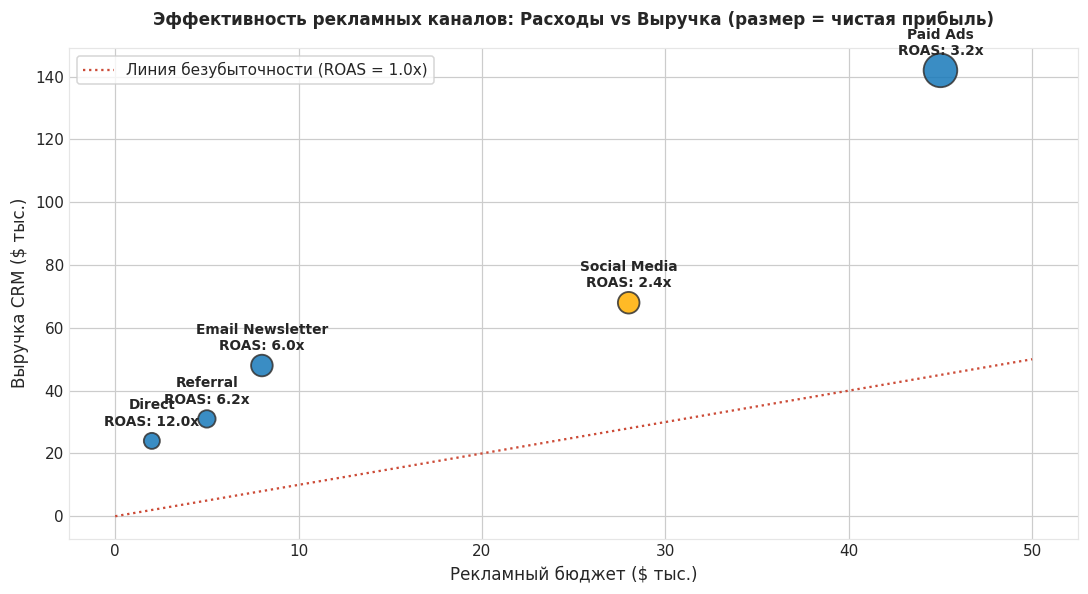

In [3]:
# Визуализация эффективности каналов (Ad Spend vs Revenue)
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=110)

colors = [PRIMARY if r >= 3.0 else WARNING if r >= 2.0 else ALERT for r in blended_df['roas']]

scatter = ax.scatter(blended_df['spend_usd'] / 1000, blended_df['revenue_usd'] / 1000,
                     s=blended_df['net_profit'] / 200, c=colors, edgecolors='#333333', linewidth=1.2, alpha=0.85)

# Линия безубыточности (ROAS = 1.0)
max_val = 50
ax.plot([0, max_val], [0, max_val], color=ALERT, linestyle=':', label='Линия безубыточности (ROAS = 1.0x)')

for _, row in blended_df.iterrows():
    ax.annotate(f"{row['channel']}\nROAS: {row['roas']:.1f}x", 
                (row['spend_usd'] / 1000, row['revenue_usd'] / 1000),
                xytext=(0, 10), textcoords="offset points", ha='center', fontweight='bold', fontsize=9)

ax.set_title("Эффективность рекламных каналов: Расходы vs Выручка (размер = чистая прибыль)", fontsize=11, fontweight='bold', pad=15)
ax.set_xlabel("Рекламный бюджет ($ тыс.)", fontsize=11)
ax.set_ylabel("Выручка CRM ($ тыс.)", fontsize=11)
ax.legend(frameon=True, facecolor='#ffffff')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет совокупного Blended ROAS
Рассчитайте средневзвешенный Blended ROAS по всем каналам компании как `общая выручка / общий бюджет`.

In [4]:
### ВАШ КОД ЗДЕСЬ
total_revenue = blended_df['revenue_usd'].sum()
total_spend = blended_df['spend_usd'].sum()
blended_roas = total_revenue / total_spend

print(f"Общий рекламный бюджет: ${total_spend:,.0f}")
print(f"Общая выручка: ${total_revenue:,.0f}")
print(f"Blended ROAS: {blended_roas:.2f}x")

assert 3.0 <= blended_roas <= 4.0, "Blended ROAS должен быть в диапазоне 3.0-4.0"
print("✅ Тест успешно пройден: смешивание данных и расчет сквозной рентабельности верны!")

Общий рекламный бюджет: $88,000
Общая выручка: $313,000
Blended ROAS: 3.56x
✅ Тест успешно пройден: смешивание данных и расчет сквозной рентабельности верны!


### 💡 Архитектурный совет по Data Blending
Data Blending в BI-интерфейсе выполняет `LEFT JOIN` на лету в браузере пользователя, что может тормозить при >50,000 записей.
Для стабильной отчетности создавайте сквозную витрину атрибуции на стороне хранилища (SQL / dbt), а не внутри Looker Studio.